# Exploratory Data Analysis

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("Data")

train_notes = pd.read_csv(DATA_DIR / "training-notes.csv")
test_notes = pd.read_csv(DATA_DIR / "test-notes.csv")
train_annotations = pd.read_csv(DATA_DIR / "train-annotations.csv")
test_annotations = pd.read_csv(DATA_DIR / "test-annotations.csv")
processed_annotations = pd.read_csv(DATA_DIR / "processed_annotations.csv")

notes = pd.concat([train_notes, test_notes], ignore_index=True)
annotations = pd.concat([train_annotations, test_annotations], ignore_index=True)

print("Notes:", notes.shape)
print("Annotations:", annotations.shape)
print("Note columns:", notes.columns.tolist())
print("Annotation columns:", annotations.columns.tolist())
print("Unique notes:", notes["note_id"].nunique())
print("Unique concepts:", annotations["concept_id"].nunique())

notes_by_id = notes.set_index("note_id")["text"]
sample_ids = annotations["note_id"].drop_duplicates().head(5)
for note_id in sample_ids:
    note_text = notes_by_id.loc[note_id]
    note_spans = annotations[annotations["note_id"] == note_id].copy()
    note_spans["entity_text"] = note_spans.apply(
        lambda row: note_text[int(row["start"]):int(row["end"])], axis=1
    )
    print(f"\nNOTE ID: {note_id} | characters: {len(note_text)}")
    print(note_text[:500].replace("\n", " "), "...")
    display(note_spans[["start", "end", "entity_text", "concept_id"]])

Notes: (272, 2)
Annotations: (74808, 4)
Note columns: ['note_id', 'text']
Annotation columns: ['note_id', 'start', 'end', 'concept_id']
Unique notes: 272
Unique concepts: 6624

NOTE ID: 10060142-DS-9 | characters: 4279
  Name:  ___                  Unit No:   ___   Admission Date:  ___              Discharge Date:   ___   Date of Birth:  ___             Sex:   M   Service: SURGERY   Allergies:  Penicillins   Attending: ___.   Chief Complaint: Biliary pancreatitis   Major Surgical or Invasive Procedure: ___: Laparoscopic cholecystectomy    History of Present Illness: Mr. ___ is a ___ man who had severe biliary  pancreatitis resulting in pancreatic necrosis for which he was  treated with nasojejunal feedings and ...


,start,end,entity_text,concept_id
0,179,190,Penicillins,91936005
1,228,248,Biliary pancreatitis,95563007
2,294,322,Laparoscopic cholecystectomy,45595009
3,390,411,biliary \npancreatitis,95563007
4,425,444,pancreatic necrosis,1835003
...,...,...,...,...
82,4038,4045,redness,822962003
83,4050,4058,drainage,75823008
84,4068,4082,incision \nsite,609343002
85,4153,4159,shower,304673006



NOTE ID: 10097089-DS-8 | characters: 7910
  Name:  ___                  Unit No:   ___   Admission Date:  ___              Discharge Date:   ___   Date of Birth:  ___             Sex:   M   Service: MEDICINE   Allergies:  No Known Allergies / Adverse Drug Reactions   Attending: ___   Chief Complaint: CHIEF COMPLAINT: Chest pain, NSTEMI   Major Surgical or Invasive Procedure: Cardiac Catheterization    History of Present Illness: ___ year old man with a h/o COPD who p/w chest pain and elevated  troponin. Had CP on ___ after eating, resol ...


,start,end,entity_text,concept_id
87,201,223,Adverse Drug Reactions,419511003
88,277,287,Chest pain,29857009
89,289,295,NSTEMI,401314000
90,336,359,Cardiac Catheterization,41976001
91,419,423,COPD,13645005
...,...,...,...,...
346,7693,7701,blockage,233970002
347,7721,7740,balloon angioplasty,233258006
348,7753,7774,increased blood \nflow,37727007
349,7782,7787,heart,80891009



NOTE ID: 10124346-DS-4 | characters: 14541
  Name:  ___              Unit No:   ___   Admission Date:  ___              Discharge Date:   ___   Date of Birth:  ___             Sex:   F   Service: MEDICINE   Allergies:  Sanctura XR   Attending: ___.   Chief Complaint: chest pain   Major Surgical or Invasive Procedure: ___ Left heart cardiac catheterization   History of Present Illness: Ms. ___ is an ___ year-old lady with a PMH of NSTEMI s/p  BMS to mid-LAD in ___, hypothyroidism and recurrent UTIs, now  presenting with chest pain, concer ...


,start,end,entity_text,concept_id
351,225,235,chest pain,29857009
352,280,314,Left heart cardiac catheterization,67629009
353,391,397,NSTEMI,401314000
354,403,406,BMS,36969009
355,410,417,mid-LAD,91748002
...,...,...,...,...
816,14137,14163,ch showed a stenosis in yo,251030009
817,14194,14198,with,36969009
818,14209,14217,nt.\n\nPle,306806004
819,14309,14316,prazole,182838006



NOTE ID: 10302979-DS-5 | characters: 10466
  Name:  ___                 Unit No:   ___   Admission Date:  ___              Discharge Date:   ___   Date of Birth:  ___             Sex:   M   Service: MEDICINE   Allergies:  Bactrim / Sulfa (Sulfonamide Antibiotics)   Attending: ___.   Chief Complaint: dyspnea   Major Surgical or Invasive Procedure: None    History of Present Illness: ___ with PMH significant for CAD s/p PCI who presents with  dyspnea associated with 4 pillow orthopnea and lower extremity  edema. The patient reports missing ...


,start,end,entity_text,concept_id
821,179,186,Bactrim,870714005
822,189,194,Sulfa,429239002
823,196,219,Sulfonamide Antibiotics,429239002
824,258,265,dyspnea,267036007
825,371,374,CAD,53741008
...,...,...,...,...
1133,10037,10047,medication,18629005
1134,10130,10144,weight goes up,262286000
1135,10188,10192,labs,15220000
1136,10193,10200,checked,239516002



NOTE ID: 10352433-DS-20 | characters: 12774
  Name:  ___                  Unit No:   ___   Admission Date:  ___              Discharge Date:   ___   Date of Birth:  ___             Sex:   M   Service: MEDICINE   Allergies:  Penicillins   Attending: ___.   Chief Complaint: Shortness of breath   Major Surgical or Invasive Procedure: None    History of Present Illness: This is a ___ year old male with history of HTN, HLD, CAD, CHF  (EF 55-60% in ___, Diabetes on insulin, hx of CVA, recently  diagnosed pericardial effusion, p/w acute-onset al ...


,start,end,entity_text,concept_id
1138,180,191,Penicillins,91936005
1139,229,248,Shortness of breath,267036007
1140,369,372,HTN,38341003
1141,374,377,HLD,55822004
1142,379,382,CAD,53741008
...,...,...,...,...
1522,12324,12330,kidney,64033007
1523,12480,12486,normal,281900007
1524,12523,12537,blood pressure,392570002
1525,12606,12633,blood pressure \nmedications,308116003


In [2]:
annotations_clean = annotations.copy()
annotations_clean["note_id"] = annotations_clean["note_id"].astype("string")
annotations_clean["concept_id"] = annotations_clean["concept_id"].astype("string").str.strip()
annotations_clean["start"] = pd.to_numeric(annotations_clean["start"], errors="coerce")
annotations_clean["end"] = pd.to_numeric(annotations_clean["end"], errors="coerce")

note_lengths = notes.set_index("note_id")["text"].str.len()
annotations_clean["note_length"] = annotations_clean["note_id"].map(note_lengths)
valid = (
    annotations_clean["start"].notna()
    & annotations_clean["end"].notna()
    & (annotations_clean["start"] >= 0)
    & (annotations_clean["end"] > annotations_clean["start"])
    & (annotations_clean["end"] <= annotations_clean["note_length"])
    & annotations_clean["concept_id"].notna()
)

annotations_clean = annotations_clean.loc[valid].copy()
annotations_clean[["start", "end"]] = annotations_clean[["start", "end"]].astype(int)
annotations_clean["entity_text"] = annotations_clean.apply(
    lambda row: notes_by_id.loc[row["note_id"]][row["start"]:row["end"]], axis=1
)
print(f"Valid annotations: {len(annotations_clean):,} / {len(annotations):,}")
annotations_clean.head()

Valid annotations: 74,808 / 74,808


,note_id,start,end,concept_id,note_length,entity_text
0,10060142-DS-9,179,190,91936005,4279,Penicillins
1,10060142-DS-9,228,248,95563007,4279,Biliary pancreatitis
2,10060142-DS-9,294,322,45595009,4279,Laparoscopic cholecystectomy
3,10060142-DS-9,390,411,95563007,4279,biliary \npancreatitis
4,10060142-DS-9,425,444,1835003,4279,pancreatic necrosis


In [3]:
annotations_clean["entity_length_chars"] = annotations_clean["end"] - annotations_clean["start"]
annotations_clean["entity_length_words"] = annotations_clean["entity_text"].str.split().str.len()

annotations_clean[["entity_length_chars", "entity_length_words"]].describe()

,entity_length_chars,entity_length_words
count,74808.000000,74808.000000
mean,9.458547,1.463052
std,7.001352,0.867742
min,1.000000,1.000000
25%,4.000000,1.000000
50%,8.000000,1.000000
75%,12.000000,2.000000
max,139.000000,18.000000


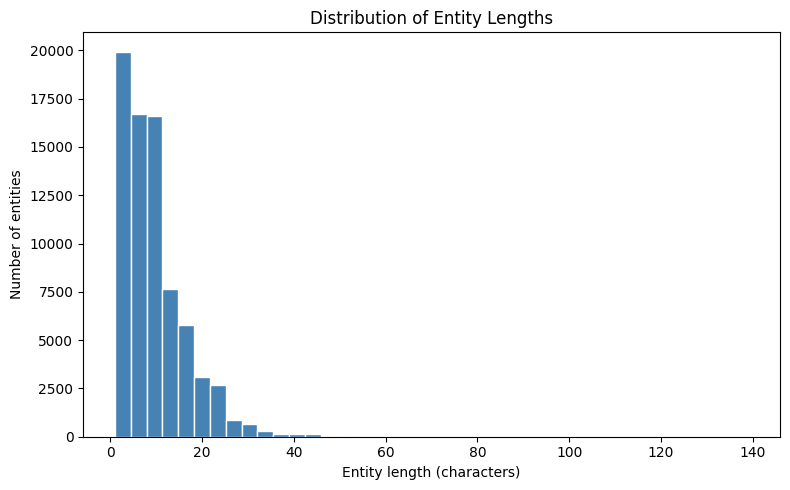

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(annotations_clean["entity_length_chars"], bins=40, color="steelblue", edgecolor="white")
plt.xlabel("Entity length (characters)")
plt.ylabel("Number of entities")
plt.title("Distribution of Entity Lengths")
plt.tight_layout()
plt.show()

In [5]:
top_codes = (
    annotations_clean["concept_id"]
    .value_counts()
    .rename_axis("concept_id")
    .reset_index(name="entity_count")
)
top_codes.head(10)

,concept_id,entity_count
0,281900007,905
1,66842004,674
2,5880005,617
3,767002,581
4,28317006,543
5,38341003,537
6,14089001,534
7,441689006,516
8,70901006,506
9,29857009,494


In [6]:
entities_per_note = (
    annotations_clean.groupby("note_id").size().reindex(notes["note_id"], fill_value=0)
)
print(f"Average entities per note: {entities_per_note.mean():.2f}")
entities_per_note.describe()

Average entities per note: 275.03


count    272.000000
mean     275.029412
std      110.380118
min       40.000000
25%      191.750000
50%      267.000000
75%      341.500000
max      674.000000
dtype: float64

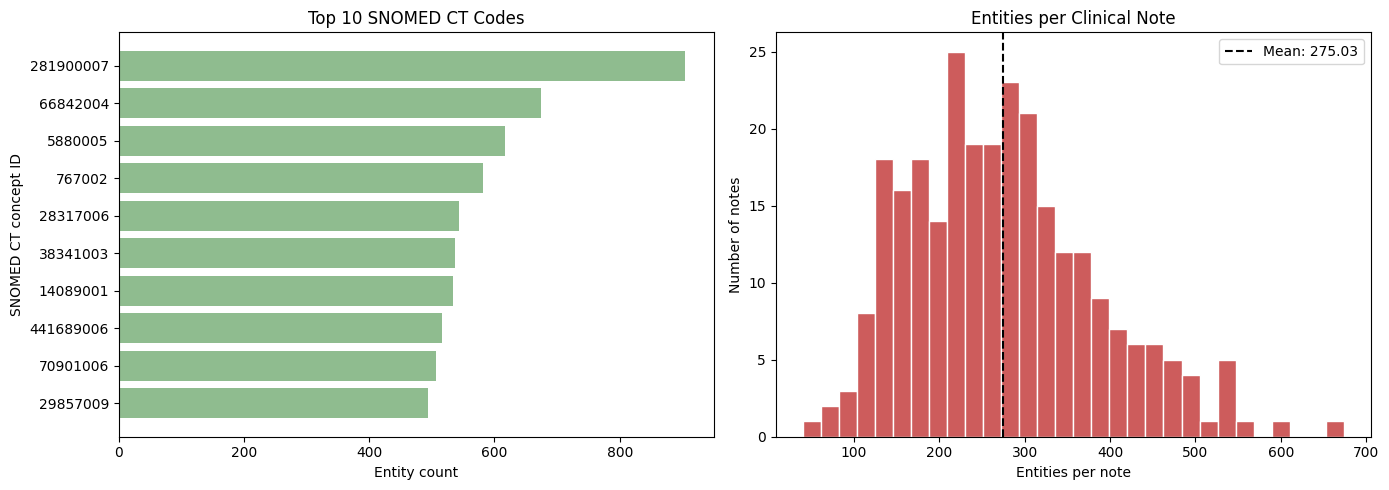

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_codes = top_codes.head(10).sort_values("entity_count")
axes[0].barh(plot_codes["concept_id"].astype(str), plot_codes["entity_count"], color="darkseagreen")
axes[0].set_xlabel("Entity count")
axes[0].set_ylabel("SNOMED CT concept ID")
axes[0].set_title("Top 10 SNOMED CT Codes")

axes[1].hist(entities_per_note, bins=30, color="indianred", edgecolor="white")
axes[1].axvline(entities_per_note.mean(), color="black", linestyle="--", label=f"Mean: {entities_per_note.mean():.2f}")
axes[1].set_xlabel("Entities per note")
axes[1].set_ylabel("Number of notes")
axes[1].set_title("Entities per Clinical Note")
axes[1].legend()

plt.tight_layout()
plt.show()